# Hand-motion excursion versus LDF and AMI peaks — Angela

Exploratory within-recording analysis: does a larger **top-to-bottom angular excursion** accompany a larger physiological peak? One cycle is bounded by consecutive detected angle troughs and contains an angle maximum. Excursion = maximum minus the preceding trough (degrees). This is a joint-angle excursion, not an absolute hand-elevation angle.

The user confirms a common recording start with approximately ±1 s uncertainty. Row alignment is the primary assumption; offsets −1, 0, +1 s are tested explicitly. Both physiological channels are sampled at 1 Hz. Sub-second timing and cycles near/below 2 s cannot be reliably resolved.

**Anatomy:** angle_1/2 = left/right elbow (shoulder–elbow–wrist); angle_3/4 = shoulder–elbow–hip, also measured at the elbow; angle_5/6 = hip. The construction notebook's shoulder labels for angle_3/4 are incorrect. Choose the moving side using the video, never by the largest physiological correlation. AMI_bloodflow is retained as the existing column name; the source AMI header reports BP(uA), so plots call it AMI signal, not blood flow or electrical flow speed. Verify instrument units before publication.

Parameters below are provisional. Inspect detection against the video and specify activity bounds before interpreting correlations. Default interval 130–299 s reproduces the existing random-forest interval; it is not independently verified as an oscillation task. Full-recording plots provide context. No input files are changed.


In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.stats import spearmanr
from IPython.display import display

BASE = Path.cwd()
if not (BASE / 'new_pose_detection').exists():
    BASE = BASE.parent
DATA_PATH = BASE / 'new_pose_detection/data/angela_final.csv'
OUT = BASE / 'new_pose_detection/peak_analysis_outputs'
OUT.mkdir(exist_ok=True)

ANGLE = 'angle_1_deg'  # left elbow; verify moving side against video
START_S, END_S = 130.0, 299.0  # set from protocol/video, not from outcome
SMOOTH_S = 3.0  # centered rolling median; also test 1 and 5 s
MIN_PEAK_DISTANCE_S = 3.0
ANGLE_PROMINENCE_DEG = 10.0
MIN_CYCLE_S, MAX_CYCLE_S = 3.0, 60.0
MIN_EXCURSION_DEG = 10.0
PHYS_PROMINENCE = {'LDF_bloodflow': 10.0, 'AMI_bloodflow': 8.0}
LAG_MIN_S, LAG_MAX_S = 0.0, 5.0  # provisional response window after angle maximum
OFFSET_S = 0.0  # positive = physiological timestamp occurs later on video clock
METRICS = ['LDF_bloodflow', 'AMI_bloodflow']
SEED = 42
N_PERMUTATIONS = 1999
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})


## Audit and full-recording context
Missing samples are not interpolated. Detection runs independently within contiguous valid segments; cycles and response windows touching a gap are excluded. The full context plot helps identify task periods and recording artifacts before choosing the analysis interval.


585 rows; 1 s/sample; 0–584 s


,missing samples
time_sec,0
angle_1_deg,2
LDF_bloodflow,10
AMI_bloodflow,10


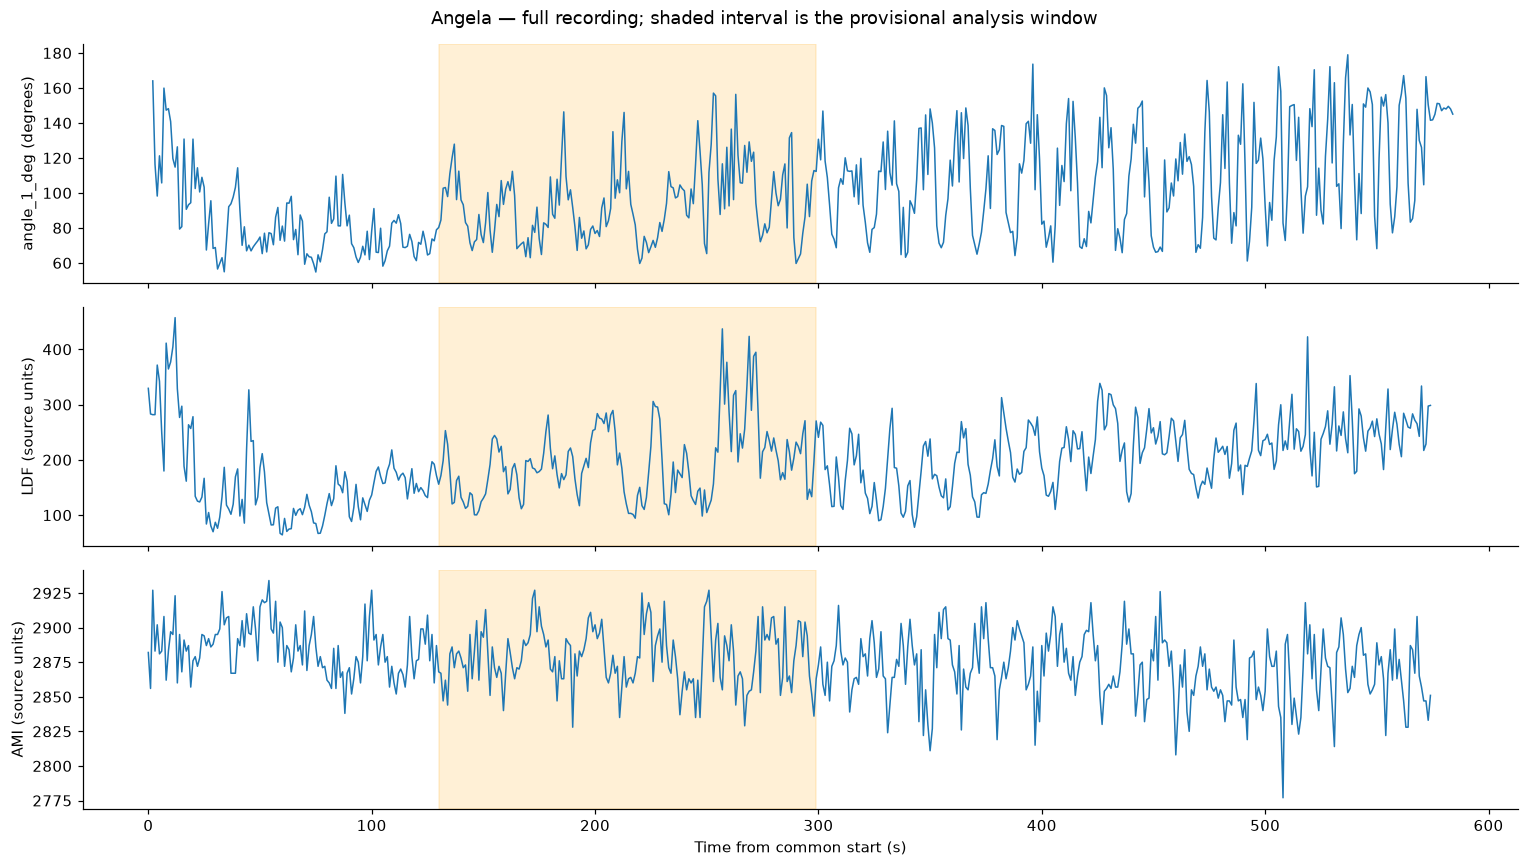

In [2]:
df = pd.read_csv(DATA_PATH).drop(columns=['Unnamed: 0'], errors='ignore')
required = ['time_sec', ANGLE] + METRICS
if not set(required).issubset(df):
    raise ValueError(f'Missing required columns: {set(required) - set(df)}')
if df.time_sec.isna().any() or not np.isfinite(df.time_sec).all() or not df.time_sec.is_monotonic_increasing or df.time_sec.duplicated().any():
    raise ValueError('Time must be finite, strictly increasing, and unique.')
dt = float(df.time_sec.diff().median())
if not np.allclose(df.time_sec.diff().dropna(), dt):
    raise ValueError('Irregular sampling: resample explicitly before this analysis.')
if not np.isclose(dt, 1.0):
    warnings.warn(f'Sample interval is {dt:g} seconds; inspect instrument timing.')
df[required] = df[required].replace([np.inf, -np.inf], np.nan)
print(f'{len(df)} rows; {dt:g} s/sample; {df.time_sec.min():g}–{df.time_sec.max():g} s')
display(df[required].isna().sum().rename('missing samples').to_frame())
fig, axs = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
for ax, col, label in zip(axs, [ANGLE]+METRICS, [ANGLE+' (degrees)', 'LDF (source units)', 'AMI (source units)']):
    ax.plot(df.time_sec, df[col], lw=1)
    ax.axvspan(START_S, END_S, color='orange', alpha=.16)
    ax.set_ylabel(label)
axs[-1].set_xlabel('Time from common start (s)')
fig.suptitle('Angela — full recording; shaded interval is the provisional analysis window')
fig.tight_layout()
fig.savefig(OUT/'01_full_recording.png', dpi=180)
plt.show()


## Detect cycles and physiological peaks independently
A rolling median reduces isolated spikes. Peak detection uses minimum prominence and separation; prominence measures height above surrounding valleys ([SciPy documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.peak_prominences.html)). All physiological peaks are detected without looking at motion values.

Each angle trough-to-trough cycle uses its highest detected angle maximum. Exclude implausible durations and small excursions. A physiological peak can be matched to at most one cycle per channel. In chronological order, choose the most prominent unused peak 0–5 s after the angle maximum, also before the next cycle's angle maximum. This assignment rule is exploratory: physiological delay and correspondence need verification, and proximity does not imply causation. Unmatched cycles remain in the exported table.


In [3]:
def segments(valid):
    edges = np.diff(np.r_[False, np.asarray(valid, bool), False].astype(int))
    return list(zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)))

def smooth_valid(values, seconds):
    arr = np.asarray(values, float)
    out = np.full(len(arr), np.nan)
    window = max(1, int(round(seconds / dt)))
    if window % 2 == 0: window += 1
    for lo, hi in segments(np.isfinite(arr)):
        out[lo:hi] = pd.Series(arr[lo:hi]).rolling(window, center=True, min_periods=1).median()
    return out

def detected(values, prominence, sign=1):
    rows = []
    distance = max(1, int(np.ceil(MIN_PEAK_DISTANCE_S/dt)))
    for lo, hi in segments(np.isfinite(values)):
        idx, props = find_peaks(sign*np.asarray(values)[lo:hi], prominence=prominence, distance=distance)
        rows.extend({'idx': int(i+lo), 'prominence': float(p)} for i, p in zip(idx, props['prominences']))
    return pd.DataFrame(rows, columns=['idx', 'prominence'])

# Include response data beyond END_S but do not include new movement cycles there.
data = df.loc[(df.time_sec >= START_S) & (df.time_sec <= END_S + LAG_MAX_S + 2)].reset_index(drop=True)
if len(data) < 10: raise ValueError('Analysis interval is too short or outside the recording.')
t = data.time_sec.to_numpy()

def extract(seconds=SMOOTH_S, angle_prom=ANGLE_PROMINENCE_DEG, phys_factor=1.0):
    sig = {col: smooth_valid(data[col], seconds) for col in [ANGLE]+METRICS}
    ap = detected(sig[ANGLE], angle_prom)
    at = detected(sig[ANGLE], angle_prom, sign=-1)
    cycles = []
    for left, right in zip(at.idx.to_numpy()[:-1], at.idx.to_numpy()[1:]):
        if t[right] > END_S or not np.isfinite(sig[ANGLE][left:right+1]).all(): continue
        duration = t[right]-t[left]
        if not MIN_CYCLE_S <= duration <= MAX_CYCLE_S: continue
        candidates = ap.loc[(ap.idx > left) & (ap.idx < right), 'idx'].to_numpy()
        if not len(candidates): continue
        peak = int(candidates[np.argmax(sig[ANGLE][candidates])])
        excursion = sig[ANGLE][peak]-sig[ANGLE][left]
        if excursion < MIN_EXCURSION_DEG: continue
        cycles.append(dict(cycle_id=len(cycles)+1, start_s=t[left], end_s=t[right],
                           angle_peak_s=t[peak], duration_s=duration,
                           trough_angle_deg=sig[ANGLE][left], peak_angle_deg=sig[ANGLE][peak],
                           excursion_deg=excursion,
                           downstroke_excursion_deg=sig[ANGLE][peak]-sig[ANGLE][right]))
    columns = ['cycle_id','start_s','end_s','angle_peak_s','duration_s','trough_angle_deg',
               'peak_angle_deg','excursion_deg','downstroke_excursion_deg']
    cyc = pd.DataFrame(cycles, columns=columns)
    peaks = {}
    for col in METRICS:
        p = detected(sig[col], PHYS_PROMINENCE[col]*phys_factor)
        p['source_time_s'] = t[p.idx.to_numpy(dtype=int)]
        p['peak_value'] = sig[col][p.idx.to_numpy(dtype=int)]
        p['raw_peak_value'] = data[col].to_numpy()[p.idx.to_numpy(dtype=int)]
        peaks[col] = p
    return sig, ap, at, cyc, peaks

def match(cyc, peaks, sig, offset=0.0):
    rows=[]
    for col in METRICS:
        used=set()
        for k, c in cyc.reset_index(drop=True).iterrows():
            start = c.angle_peak_s + LAG_MIN_S
            stop = c.angle_peak_s + LAG_MAX_S
            next_peak = cyc.iloc[k+1].angle_peak_s if k+1 < len(cyc) else np.inf
            stop = min(stop, next_peak - dt*1e-6)
            source_start, source_stop = start-offset, stop-offset
            row = dict(c.to_dict(), metric=col, offset_s=offset, matched=False,
                       response_start_s=start, response_end_s=stop,
                       phys_peak_s=np.nan, lag_s=np.nan, peak_value=np.nan,
                       prominence=np.nan, raw_peak_value=np.nan)
            # Require the entire window inside the recording and free of missing samples.
            mask = (t >= source_start) & (t <= source_stop)
            if source_start < t[0] or source_stop > t[-1] or not mask.any() or not np.isfinite(sig[col][mask]).all():
                row['status']='incomplete response window'
            else:
                p = peaks[col]
                cand=p.loc[(p.source_time_s >= source_start) & (p.source_time_s <= source_stop) & ~p.idx.isin(used)]
                row['status']='no qualifying peak'
                if len(cand):
                    best=cand.sort_values(['prominence','source_time_s'], ascending=[False,True]).iloc[0]
                    used.add(int(best.idx))
                    pt=best.source_time_s+offset
                    row.update(matched=True, status='matched', phys_peak_s=pt, lag_s=pt-c.angle_peak_s,
                               peak_value=best.peak_value, prominence=best.prominence, raw_peak_value=best.raw_peak_value)
            rows.append(row)
    cols=list(cyc.columns)+['metric','offset_s','matched','response_start_s','response_end_s','phys_peak_s',
                            'lag_s','peak_value','prominence','raw_peak_value','status']
    return pd.DataFrame(rows, columns=cols)

sig, angle_peaks, angle_troughs, cycles, physiological_peaks = extract()
matches = match(cycles, physiological_peaks, sig, OFFSET_S)
print(f'{len(cycles)} retained cycles. These must be checked against the video.')
display(cycles)
display(matches.groupby('metric').agg(cycles=('cycle_id','size'), matched=('matched','sum')) if len(matches) else matches)


10 retained cycles. These must be checked against the video.


,cycle_id,start_s,end_s,angle_peak_s,duration_s,trough_angle_deg,peak_angle_deg,excursion_deg,downstroke_excursion_deg
0,1,144.0,170.0,162.0,26.0,71.498342,106.414434,34.916092,42.857341
1,2,170.0,196.0,185.0,26.0,63.557093,120.518674,56.961581,50.218003
2,3,196.0,220.0,212.0,24.0,70.300671,129.308296,59.007625,66.583098
3,4,220.0,241.0,233.0,21.0,62.725198,103.583075,40.857877,16.333122
4,5,241.0,249.0,246.0,8.0,87.249953,123.959420,36.709467,52.884705
5,6,249.0,257.0,253.0,8.0,71.074715,155.475646,84.400931,64.562121
6,7,257.0,261.0,258.0,4.0,90.913525,116.637665,25.724140,20.478951
7,8,261.0,265.0,262.0,4.0,96.158714,136.471008,40.312294,30.656897
8,9,265.0,274.0,268.0,9.0,105.814111,127.128756,21.314645,51.387494
9,10,274.0,290.0,287.0,16.0,75.741262,131.471826,55.730564,69.027625


,cycles,matched
metric,,
AMI_bloodflow,10,5
LDF_bloodflow,10,6


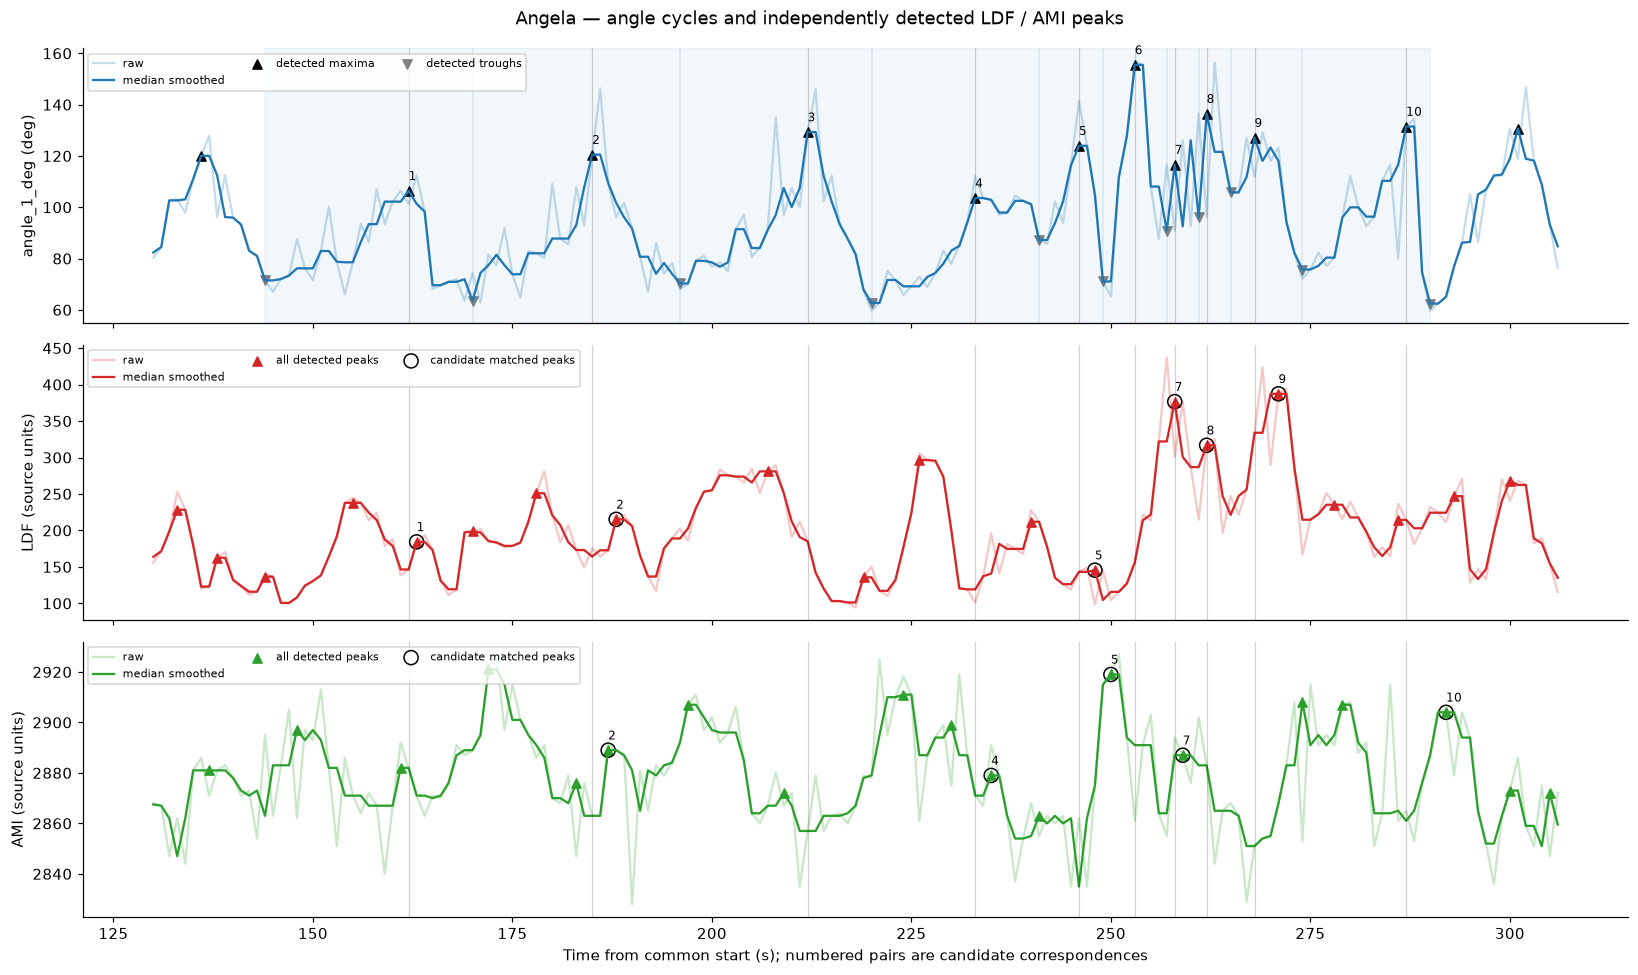

In [4]:
fig, axs = plt.subplots(3,1,figsize=(15,9),sharex=True)
for ax, col, color in zip(axs, [ANGLE]+METRICS, ['tab:blue','tab:red','tab:green']):
    tx = t if col == ANGLE else t+OFFSET_S
    ax.plot(tx, data[col], color=color, alpha=.25, label='raw')
    ax.plot(tx, sig[col], color=color, lw=1.5, label='median smoothed')
    if col == ANGLE:
        ax.scatter(t[angle_peaks.idx], sig[col][angle_peaks.idx], marker='^', color='black', label='detected maxima')
        ax.scatter(t[angle_troughs.idx], sig[col][angle_troughs.idx], marker='v', color='gray', label='detected troughs')
        for c in cycles.itertuples():
            ax.axvspan(c.start_s,c.end_s,alpha=.06,color=color)
            ax.annotate(str(c.cycle_id),(c.angle_peak_s,c.peak_angle_deg),xytext=(0,7),textcoords='offset points',fontsize=8)
    else:
        p=physiological_peaks[col]
        ax.scatter(p.source_time_s+OFFSET_S,p.peak_value,color=color,marker='^',label='all detected peaks')
        m=matches.loc[(matches.metric==col)&matches.matched]
        ax.scatter(m.phys_peak_s,m.peak_value,s=85,facecolors='none',edgecolors='black',label='candidate matched peaks')
        for r in m.itertuples():
            ax.annotate(str(int(r.cycle_id)),(r.phys_peak_s,r.peak_value),xytext=(0,7),textcoords='offset points',fontsize=8)
    for c in cycles.itertuples(): ax.axvline(c.angle_peak_s,color='black',alpha=.18,lw=.8)
    ax.set_ylabel(ANGLE+' (deg)' if col==ANGLE else col.replace('_bloodflow','')+' (source units)')
    ax.legend(loc='upper left',fontsize=7,ncol=3)
axs[-1].set_xlabel('Time from common start (s); numbered pairs are candidate correspondences')
fig.suptitle('Angela — angle cycles and independently detected LDF / AMI peaks')
fig.tight_layout()
fig.savefig(OUT/'02_matched_peaks.png',dpi=180)
plt.show()


## Association of excursion with peak size
Report Spearman rank correlations for raw peak value (affected by slow baseline drift) and prominence (height above surrounding valleys). Peak prominence is the primary exploratory size measure. A time-adjusted rank correlation checks whether a shared slow trend could explain the relationship.

The circular-shift diagnostic rotates the physiological trace, **redetects its peaks, and repeats the same matching rule**, preserving much of its temporal dependence. Only complete physiological segments can be tested; shift-boundary peaks within the smoothing/separation margin are excluded. All nonzero circular shifts are evaluated, including small shifts, making this diagnostic conservative for periodic signals. It assumes approximate stationarity, is not a confirmatory test, and is not reliable for major task changes. Naive samplewise p-values are deliberately omitted. One participant's cycles are not independent participants. Small matched samples and restricted excursion ranges can make correlation unstable. Correlations are suppressed below five matched cycles, and time-adjusted correlations below six; these are reporting safeguards, not proof that larger samples are adequate.


,metric,outcome,n_matched,spearman_rho,time_adjusted_rank_r,median_lag_s,excursion_min_deg,excursion_max_deg
0,LDF_bloodflow,prominence,6,-0.600000,-0.525487,1.5,21.314645,56.961581
1,LDF_bloodflow,peak_value,6,-0.542857,-0.369175,1.5,21.314645,56.961581
2,AMI_bloodflow,prominence,5,0.100000,NaN,2.0,25.724140,56.961581
3,AMI_bloodflow,peak_value,5,0.100000,NaN,2.0,25.724140,56.961581


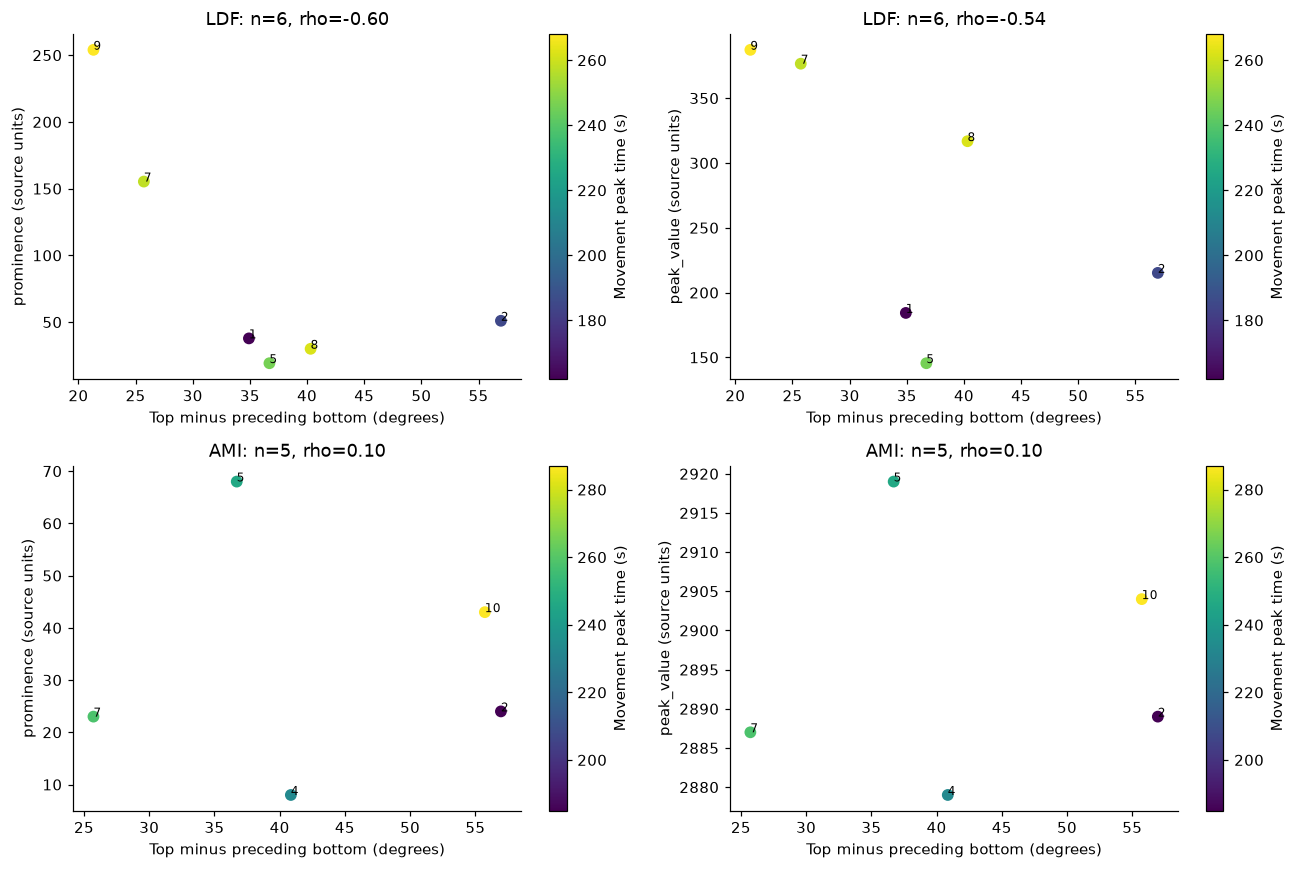

,metric,observed_rho,n_valid_shifts,shift_diagnostic_p
0,LDF_bloodflow,-0.6,142,0.237762
1,AMI_bloodflow,0.1,132,0.766917


In [5]:
def rho(x,y):
    x,y=np.asarray(x,float),np.asarray(y,float)
    ok=np.isfinite(x)&np.isfinite(y)
    if ok.sum()<5 or np.ptp(x[ok])==0 or np.ptp(y[ok])==0: return np.nan
    return float(spearmanr(x[ok],y[ok]).statistic)

def time_adjusted(m, outcome):
    if len(m)<6: return np.nan
    ranks=m[['excursion_deg',outcome,'angle_peak_s']].rank().to_numpy()
    design=np.column_stack([np.ones(len(m)),ranks[:,2]])
    residual=ranks[:,:2]-design@np.linalg.lstsq(design,ranks[:,:2],rcond=None)[0]
    if (residual.std(axis=0)<1e-10).any(): return np.nan
    return float(np.corrcoef(residual.T)[0,1])

summary=[]
for col in METRICS:
    m=matches.loc[(matches.metric==col)&matches.matched]
    for outcome in ['prominence','peak_value']:
        summary.append(dict(metric=col,outcome=outcome,n_matched=len(m),
                            spearman_rho=rho(m.excursion_deg,m[outcome]),
                            time_adjusted_rank_r=time_adjusted(m,outcome),
                            median_lag_s=m.lag_s.median(),
                            excursion_min_deg=m.excursion_deg.min(),excursion_max_deg=m.excursion_deg.max()))
summary=pd.DataFrame(summary)
display(summary)
fig,axs=plt.subplots(2,2,figsize=(12,8),squeeze=False)
for i,col in enumerate(METRICS):
    m=matches.loc[(matches.metric==col)&matches.matched]
    for j,outcome in enumerate(['prominence','peak_value']):
        ax=axs[i,j]
        scatter=ax.scatter(m.excursion_deg,m[outcome],c=m.angle_peak_s,cmap='viridis',s=45)
        for r in m.itertuples(): ax.annotate(str(int(r.cycle_id)),(r.excursion_deg,getattr(r,outcome)),fontsize=8)
        ax.set(xlabel='Top minus preceding bottom (degrees)',ylabel=outcome+' (source units)',
               title=f'{col.split("_")[0]}: n={len(m)}, rho={rho(m.excursion_deg,m[outcome]):.2f}')
        fig.colorbar(scatter,ax=ax,label='Movement peak time (s)')
fig.tight_layout()
fig.savefig(OUT/'03_excursion_associations.png',dpi=180)
plt.show()

null_rows=[]
for col in METRICS:
    observed=summary.loc[(summary.metric==col)&(summary.outcome=='prominence'),'spearman_rho'].iloc[0]
    values=sig[col]
    if not np.isfinite(values).all() or not np.isfinite(observed):
        null_rows.append(dict(metric=col,observed_rho=observed,n_valid_shifts=0,shift_diagnostic_p=np.nan))
        continue
    shifts=np.arange(1,len(values))
    if len(shifts)>N_PERMUTATIONS:
        shifts=np.random.default_rng(SEED).choice(shifts,N_PERMUTATIONS,replace=False)
    null=[]
    margin=max(int(np.ceil(SMOOTH_S/dt)),int(np.ceil(MIN_PEAK_DISTANCE_S/dt)))
    for shift in shifts:
        shifted=np.roll(values,int(shift)).copy()
        shifted[max(0,shift-margin):min(len(shifted),shift+margin+1)]=np.nan
        p=detected(shifted,PHYS_PROMINENCE[col])
        ix=p.idx.to_numpy(dtype=int)
        p['source_time_s']=t[ix]; p['peak_value']=shifted[ix]; p['raw_peak_value']=np.nan
        trial=match(cycles,{**physiological_peaks,col:p},{**sig,col:shifted},OFFSET_S)
        mm=trial.loc[(trial.metric==col)&trial.matched]
        rr=rho(mm.excursion_deg,mm.prominence)
        if np.isfinite(rr): null.append(rr)
    pval=(1+np.sum(np.abs(null)>=abs(observed)))/(1+len(null)) if len(null)>=20 else np.nan
    null_rows.append(dict(metric=col,observed_rho=observed,n_valid_shifts=len(null),shift_diagnostic_p=pval))
null_summary=pd.DataFrame(null_rows)
display(null_summary)


## Timing and detection sensitivity
All combinations below are reported, not used to select the strongest correlation. Offsets shift physiological timestamps relative to video (positive = later). Compare sign, magnitude, match count, and cycle count across plausible preprocessing settings. A finding that disappears under ±1 s timing uncertainty or modest threshold changes is fragile. This grid does not cover all sources of uncertainty.


,metric,smooth_s,angle_prominence_deg,phys_prominence_factor,offset_s,n_cycles,n_matched,rho_prominence,rho_peak_value
78,LDF_bloodflow,3.0,10.0,1.0,-1.0,10,7,0.107143,-0.178571
79,AMI_bloodflow,3.0,10.0,1.0,-1.0,10,6,-0.257143,-0.257143
80,LDF_bloodflow,3.0,10.0,1.0,0.0,10,6,-0.600000,-0.542857
81,AMI_bloodflow,3.0,10.0,1.0,0.0,10,5,0.100000,0.100000
82,LDF_bloodflow,3.0,10.0,1.0,1.0,10,7,-0.607143,-0.428571
83,AMI_bloodflow,3.0,10.0,1.0,1.0,10,5,0.100000,0.100000


,n_settings,finite_rho,rho_min,rho_median,rho_max,matched_min,matched_max
metric,,,,,,,
AMI_bloodflow,81,53,-0.5,-0.204713,0.300000,1,17
LDF_bloodflow,81,72,-1.0,-0.209524,0.196078,4,18


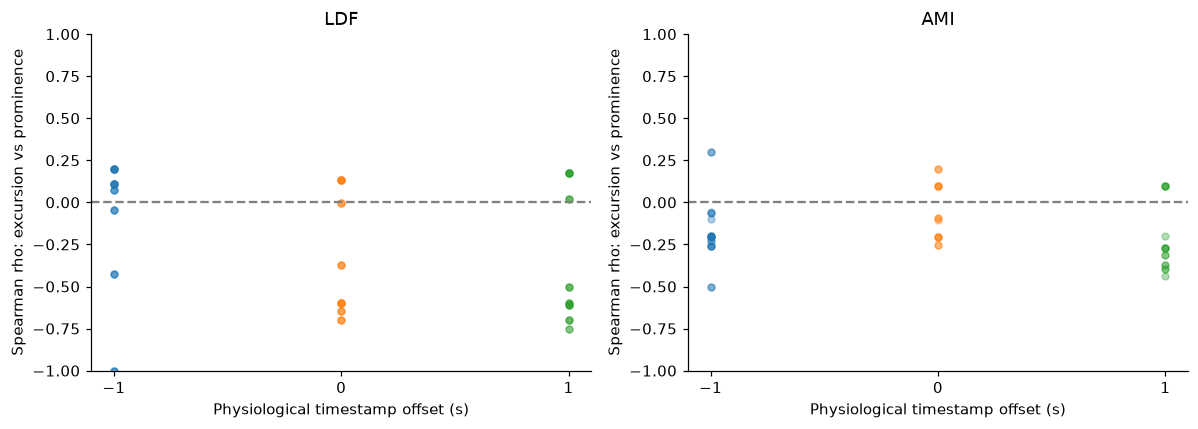

In [6]:
sensitivity=[]
for seconds in [1.0,3.0,5.0]:
    for angle_prom in [7.5,10.0,15.0]:
        for phys_factor in [.75,1.0,1.5]:
            ss,_,_,cc,pp=extract(seconds,angle_prom,phys_factor)
            for offset in [-1.0,0.0,1.0]:
                mm=match(cc,pp,ss,offset)
                for col in METRICS:
                    matched=mm.loc[(mm.metric==col)&mm.matched]
                    sensitivity.append(dict(metric=col,smooth_s=seconds,angle_prominence_deg=angle_prom,
                                            phys_prominence_factor=phys_factor,offset_s=offset,n_cycles=len(cc),
                                            n_matched=len(matched),rho_prominence=rho(matched.excursion_deg,matched.prominence),
                                            rho_peak_value=rho(matched.excursion_deg,matched.peak_value)))
sensitivity=pd.DataFrame(sensitivity)
primary_offsets=sensitivity.loc[(sensitivity.smooth_s==SMOOTH_S)&
                               (sensitivity.angle_prominence_deg==ANGLE_PROMINENCE_DEG)&
                               (sensitivity.phys_prominence_factor==1)]
display(primary_offsets)
display(sensitivity.groupby('metric').agg(n_settings=('offset_s','size'),
    finite_rho=('rho_prominence','count'),rho_min=('rho_prominence','min'),rho_median=('rho_prominence','median'),
    rho_max=('rho_prominence','max'),matched_min=('n_matched','min'),matched_max=('n_matched','max')))
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,col in zip(axs,METRICS):
    s=sensitivity.loc[sensitivity.metric==col]
    for offset in [-1,0,1]:
        v=s.loc[s.offset_s==offset,'rho_prominence'].dropna()
        ax.scatter(np.full(len(v),offset),v,alpha=.35,s=20)
    ax.axhline(0,color='gray',ls='--')
    ax.set(title=col.split('_')[0],xlabel='Physiological timestamp offset (s)',ylabel='Spearman rho: excursion vs prominence',xticks=[-1,0,1],ylim=(-1,1))
fig.tight_layout()
fig.savefig(OUT/'04_sensitivity.png',dpi=180)
plt.show()


In [7]:
cycles.to_csv(OUT/'cycles.csv',index=False)
matches.to_csv(OUT/'matched_peaks.csv',index=False)
summary.to_csv(OUT/'association_summary.csv',index=False)
null_summary.to_csv(OUT/'circular_shift_diagnostic.csv',index=False)
sensitivity.to_csv(OUT/'sensitivity.csv',index=False)
for col,p in physiological_peaks.items(): p.to_csv(OUT/f'{col}_detected_peaks.csv',index=False)
config={key:globals()[key] for key in ['ANGLE','START_S','END_S','SMOOTH_S','MIN_PEAK_DISTANCE_S',
        'ANGLE_PROMINENCE_DEG','MIN_CYCLE_S','MAX_CYCLE_S','MIN_EXCURSION_DEG','PHYS_PROMINENCE',
        'LAG_MIN_S','LAG_MAX_S','OFFSET_S','SEED','N_PERMUTATIONS']}
(OUT/'settings.json').write_text(json.dumps(config,indent=2))
print(f'Figures and tables saved to {OUT}')


Figures and tables saved to C:\Users\Qijun Ma\Documents\GitHub\Analysis-Scripts\pose_analysis\new_pose_detection\peak_analysis_outputs


## What can be claimed?

This notebook can describe candidate temporal correspondences and estimate an exploratory within-person association between joint-angle excursion and physiological peak magnitude. It cannot establish that hand motion caused a peak or establish a population effect from Angela alone. Peaks may also reflect motion artifacts, contact changes, shared periodicity, or slow drift.

Before submission:
- Verify selected angle/side, activity interval, and cycle numbering against the video. Keep exclusions and matching choices independent of LDF/AMI results.
- Confirm the ±1 s synchronization assumption and instrument units. A physiological lag is distinct from a clock offset.
- Look at unmatched cycles, raw traces, time-adjusted results, and the entire sensitivity grid; do not select the best setting or angle to obtain significance.
- Analyze the same prespecified settings in other participants, reporting participant-level effects rather than pooling every cycle as independent evidence. If you alter choices after viewing these results, label this analysis exploratory and validate separately.
- Report effect size, usable/matched cycle counts, timing uncertainty, and null or inconsistent results. Peak detection is useful even when the excursion–amplitude association is weak.
